# Seeing if my friend is healthy, or has Crohns or UC by looking at data on fecal calprotectin, age, sex, smoking, location, socioeconomic status

This is using a dataset I found on Kaggle and one posted on Research Gate. This woud be hypothetically looking at how Crohns often takes ages to get diagnosed. Forming effective models that could be used to streamline diagnosis.

In [ ]:
import os

os.makedirs('/root/.config/kaggle', exist_ok=True)
with open('/root/.config/kaggle/kaggle.json', 'w') as f:
    f.write('{"username":"tillyalford","key":"KGAT_0a41dfbea8c27ffbb1353f7909ae068f"}')
os.chmod('/root/.config/kaggle/kaggle.json', 600)

In [ ]:
!pip install kaggle -q
!kaggle datasets download -d qasimhu/human-gut-microbiome-atlas-hmp2
!unzip human-gut-microbiome-atlas-hmp2.zip -d hmp2_data/
!ls hmp2_data/

Dataset URL: https://www.kaggle.com/datasets/qasimhu/human-gut-microbiome-atlas-hmp2
License(s): Attribution 4.0 International (CC BY 4.0)
100% 804k/804k [00:00<00:00, 113MB/s]

Archive:  human-gut-microbiome-atlas-hmp2.zip
  inflating: hmp2_data/hmp2_ibd_metagenomics_atlas_20260219_121629.csv  
hmp2_ibd_metagenomics_atlas_20260219_121629.csv


In [ ]:
import pandas as pd
df = pd.read_csv('hmp2_data/hmp2_ibd_metagenomics_atlas_20260219_121629.csv')
df.head()

,External ID,Participant ID,week_num,diagnosis,fecalcal,Bacteroides vulgatus,Bacteroides uniformis,Bacteroides thetaiotaomicron,Faecalibacterium prausnitzii,Roseburia faecis,...,Prevotella histicola,Prevotella pallens,Chlamydia ibidis,Enterococcus mundtii,Anaerostipes sp 992a,Actinobaculum sp oral taxon 183,Lachnoclostridium sp An298,Haemophilus haemolyticus,Enterococcus dispar,Atopobium minutum
0,CSM5FZ3N,C3001,0.0,Crohns Disease,193.89000,42.34520,31.29744,6.81155,5.29200,5.01599,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,CSM5FZ4C,C3001,8.0,Crohns Disease,61.34000,12.29822,28.74672,26.46909,2.74544,2.73659,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,CSM5MCVV,C3001,16.0,Crohns Disease,115.27000,12.38214,15.91063,3.77383,0.25195,0.24233,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,CSM67UA2,C3001,28.0,Crohns Disease,23.20350,36.69818,28.04901,16.81345,1.25428,1.94912,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,CSM79HGP,C3001,38.0,Crohns Disease,37.17836,33.26674,36.24943,7.88757,1.20698,1.48374,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Ok so basically, I'm going to have a little look at this data, get some visualisations, and then see if my friend (who has crohns) has crohns.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3387 entries, 0 to 3386
Columns: 571 entries, External ID to Atopobium minutum
dtypes: float64(568), object(3)
memory usage: 14.8+ MB


In [ ]:
# From my previous peak at the data there should be 3 diagnosis options
# Crohns, Ulterative Colitis, Healthy
print(df['diagnosis'].value_counts())

diagnosis
Crohns Disease        1608
Ulcerative Colitis     913
Healthy                866
Name: count, dtype: int64


From my friend I'm gonna get her fecalcal and compare it to the data provided, we are going to have a little peak at how that looks visually.

/tmp/ipykernel_9383/4277210330.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y='fecalcal',
/tmp/ipykernel_9383/4277210330.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df, x='diagnosis', y='fecalcal',


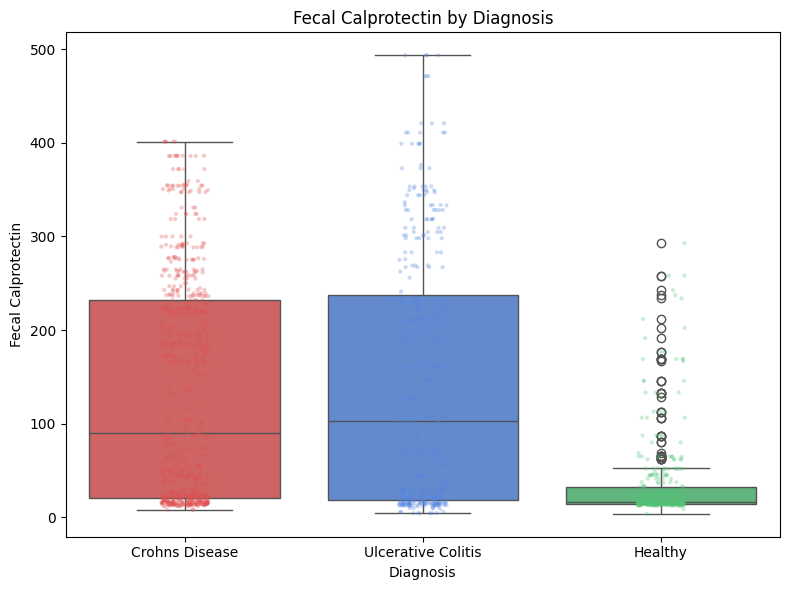

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='diagnosis', y='fecalcal',
            palette={'Crohns Disease': '#e05252', 'Ulcerative Colitis': '#5285e0', 'Healthy': '#52c478'})
sns.stripplot(data=df, x='diagnosis', y='fecalcal',
              palette={'Crohns Disease': '#e05252', 'Ulcerative Colitis': '#5285e0', 'Healthy': '#52c478'},
              alpha=0.3, size=3, jitter=True)

plt.title('Fecal Calprotectin by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Fecal Calprotectin')
plt.tight_layout()
plt.show()

(From SA Health): Faecal calprotectin is a measure of intestinal inflammation. A POSITIVE result (>100 ug/g) is 97% sensitive for inflammatory bowel disease over irritable bowel syndrome. The degree of inflammation correlates with the level and thus can be used for monitoring. High levels (>250ug/g) are consistent with significant bowel inflammation and aid in determining clinical disease activity. The low positive result may be found in many conditions including inflammatory bowel disease, bacterial infections or colorectal carcinoma.

My friend rated 523 AHHHHHHH.

In [ ]:
print(df[['fecalcal', 'diagnosis']].describe())
print(df[['fecalcal', 'diagnosis']].isnull().sum())

          fecalcal
count  1360.000000
mean    112.464996
std     119.385625
min       3.620000
25%      16.000000
50%      44.012000
75%     211.241975
max     493.700000
fecalcal     2027
diagnosis       0
dtype: int64


Ah we have so much missing data!! cause we have 3387 rows,  so that we aren't miscalculating or misrepresenting this data we will just delete them, since 1360 is still a decent amount to be working with, and since this is a really good indicator of crohns.

In [ ]:
df_model1 = df[['fecalcal', 'diagnosis']].dropna()
print(df_model1.shape)
print(df_model1['diagnosis'].value_counts())

(1360, 2)
diagnosis
Crohns Disease        645
Ulcerative Colitis    363
Healthy               352
Name: count, dtype: int64


Although we have significantly less data, its not too bad because the data spread is not too uneven. We gonna use a simple random forest classifier here.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X = df_model1[['fecalcal']]
y = df_model1['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model1 = RandomForestClassifier(n_estimators=100, random_state=42)
model1.fit(X_train, y_train)

print(classification_report(y_test, model1.predict(X_test)))

                    precision    recall  f1-score   support

    Crohns Disease       0.90      0.95      0.92       129
           Healthy       0.95      0.91      0.93        69
Ulcerative Colitis       0.93      0.88      0.90        74

          accuracy                           0.92       272
         macro avg       0.93      0.91      0.92       272
      weighted avg       0.92      0.92      0.92       272



In [ ]:
import numpy as np

friends_fecalcal = [[523]]
prediction = model1.predict(friends_fecalcal)
probability = model1.predict_proba(friends_fecalcal)

print("Prediction:", prediction[0])
print("\nProbabilities:")
for diag, prob in zip(model1.classes_, probability[0]):
    print(f"  {diag}: {prob*100:.1f}%")

Prediction: Ulcerative Colitis

Probabilities:
  Crohns Disease: 0.0%
  Healthy: 0.0%
  Ulcerative Colitis: 100.0%


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


This model registers her as Ulcerative Colitis, but thats not suprising since they present similarly, the model is extremely confident in this prediction though which indicates that she is definitely not healthy. She was actually higher than all of my data, poor pet.

Before I do some machine learning stuff, i want to look at some stats into some other discrete information like age, sex, smoking... i want to input her answers into this to see what i predict her to be. Since a lot of these features do not actually impact Crohns i think it will be interesting to see what it says. The data i used for this is from https://www.researchgate.net/figure/Prevalence-per-100-000-of-IBD-Crohns-disease-and-ulcerative-colitis-stratified-by_tbl2_351921486.

Actually I might compare the features beforehand because that has piqued my curiousity.


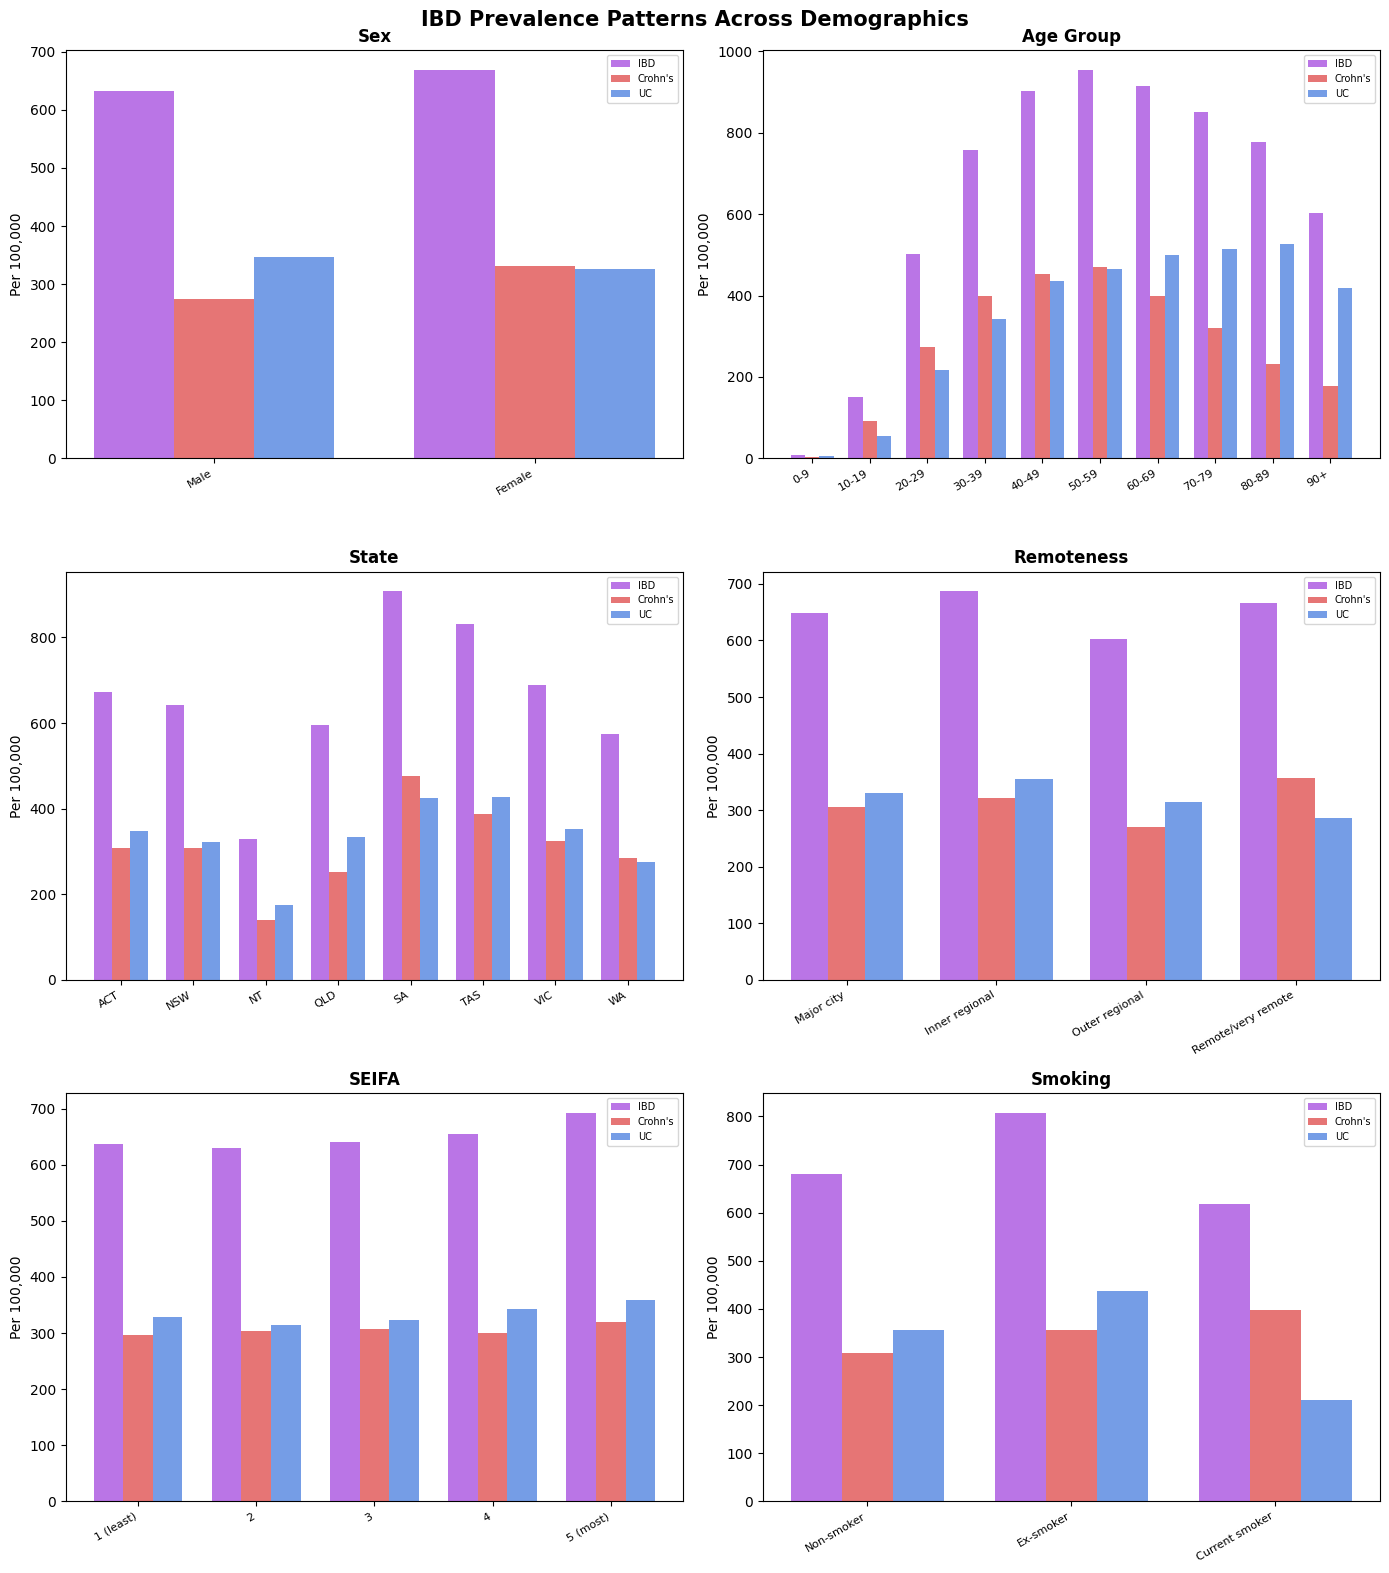

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
axes = axes.flatten()

categories = {
    'Sex': {
        'Male':   (633, 275, 346),
        'Female': (669, 331, 326),
    },
    'Age Group': {
        '0-9':  (9, 3, 5),
        '10-19': (151, 93, 55),
        '20-29': (503, 274, 217),
        '30-39': (757, 399, 343),
        '40-49': (902, 452, 436),
        '50-59': (954, 471, 465),
        '60-69': (914, 398, 499),
        '70-79': (850, 320, 515),
        '80-89': (776, 233, 527),
        '90+':   (603, 179, 418),
    },
    'State': {
        'ACT': (673, 309, 347),
        'NSW': (643, 308, 323),
        'NT':  (330, 139, 174),
        'QLD': (596, 253, 334),
        'SA':  (908, 476, 424),
        'TAS': (831, 388, 428),
        'VIC': (689, 324, 352),
        'WA':  (574, 285, 275),
    },
    'Remoteness': {
        'Major city':       (648, 306, 330),
        'Inner regional':   (687, 322, 355),
        'Outer regional':   (602, 271, 315),
        'Remote/very remote': (666, 357, 286),
    },
    'SEIFA': {
        '1 (least)': (637, 296, 328),
        '2':         (630, 304, 314),
        '3':         (641, 307, 324),
        '4':         (655, 301, 343),
        '5 (most)':  (693, 320, 359),
    },
    'Smoking': {
        'Non-smoker':    (680, 309, 356),
        'Ex-smoker':     (808, 356, 438),
        'Current smoker': (619, 398, 210),
    },
}

colors = {"Crohn's": '#e05252', 'UC': '#5285e0', 'IBD': '#a952e0'}

for ax, (cat, data) in zip(axes, categories.items()):
    labels = list(data.keys())
    ibd = [v[0] for v in data.values()]
    cd  = [v[1] for v in data.values()]
    uc  = [v[2] for v in data.values()]
    x = np.arange(len(labels))
    w = 0.25

    ax.bar(x - w, ibd, w, label='IBD', color='#a952e0', alpha=0.8)
    ax.bar(x,     cd,  w, label="Crohn's", color='#e05252', alpha=0.8)
    ax.bar(x + w, uc,  w, label='UC', color='#5285e0', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    ax.set_title(cat, fontweight='bold')
    ax.set_ylabel('Per 100,000')
    ax.legend(fontsize=7)

plt.suptitle('IBD Prevalence Patterns Across Demographics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Since beforehand we looked at Crohns and UC and i misdiagnosed her, i might just consider those two, im basically going to use this possibly irrelevant data to see if it will tell us which one she has.

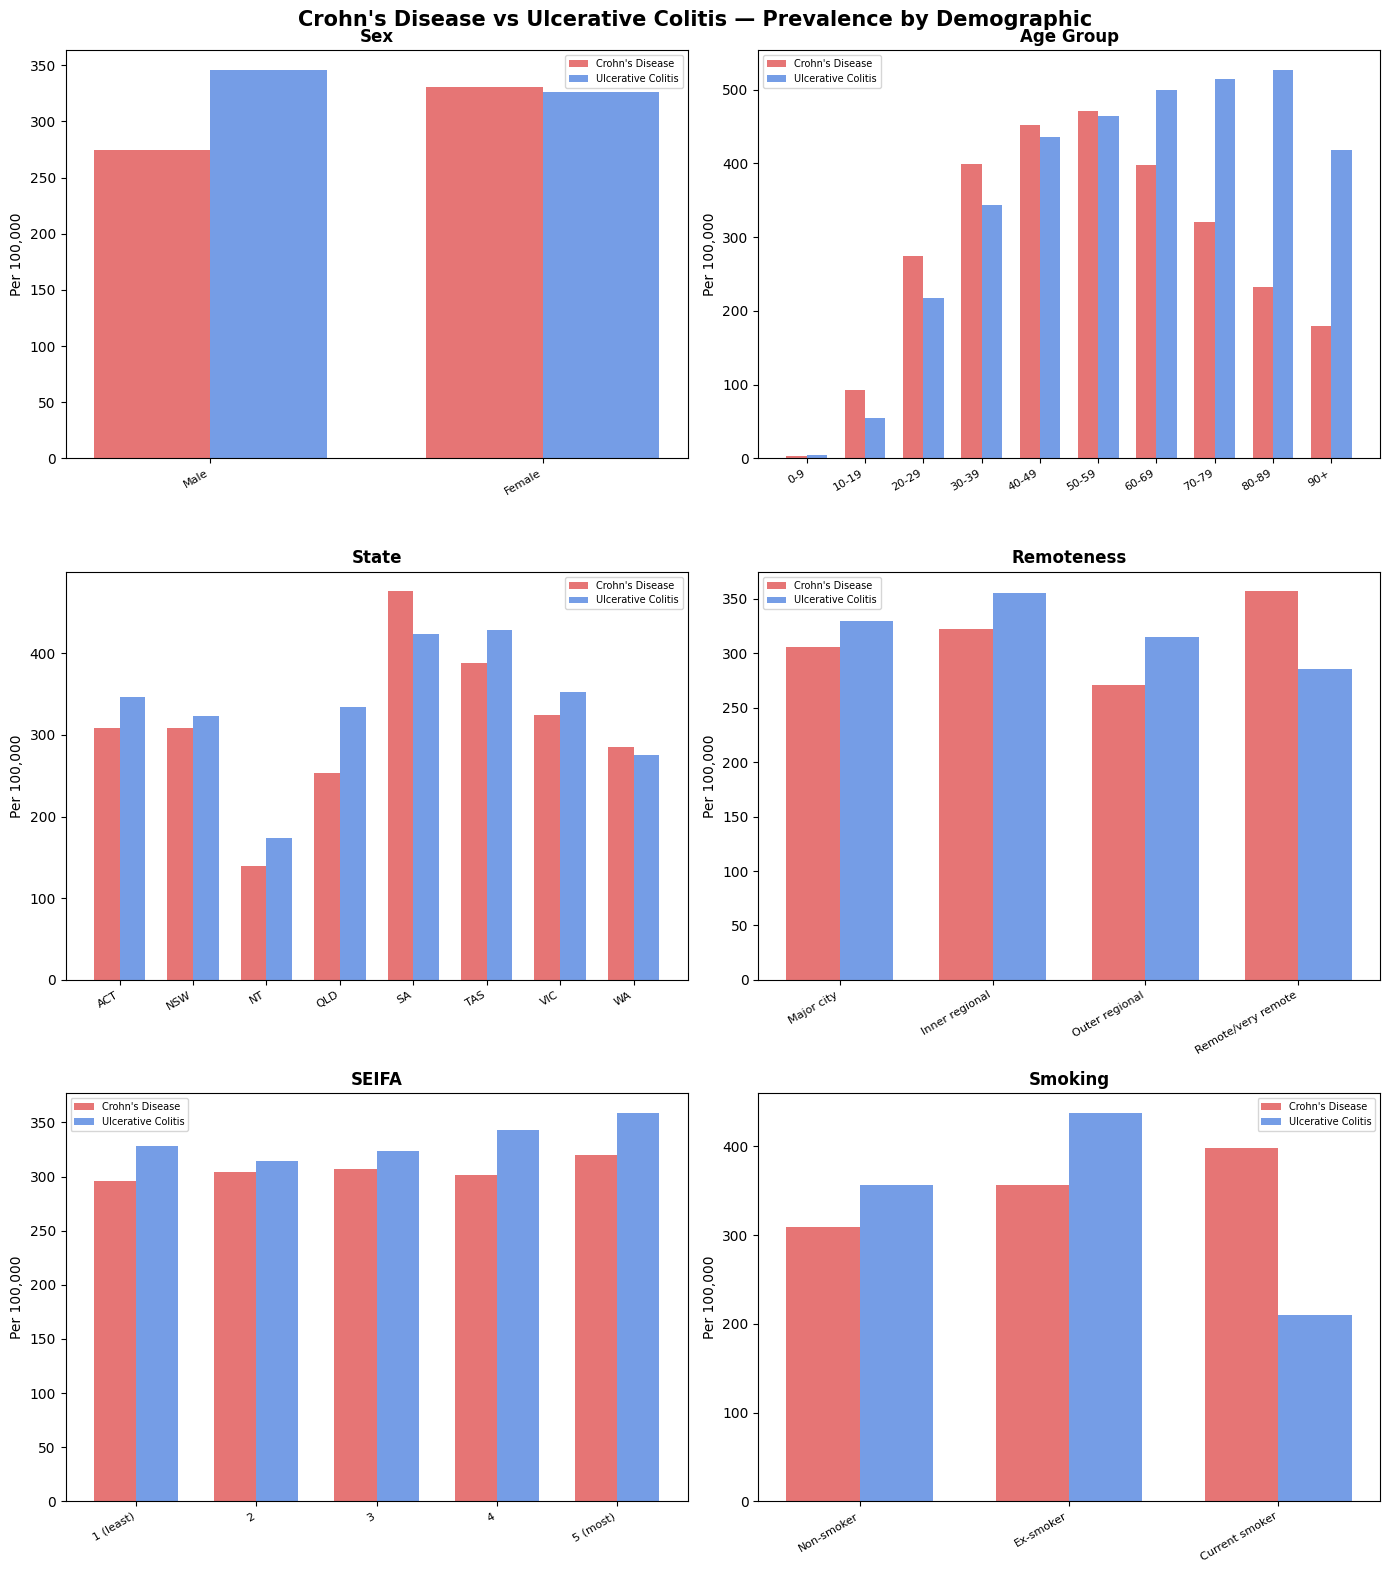

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
axes = axes.flatten()

categories = {
    'Sex': {
        'Male':   (275, 346),
        'Female': (331, 326),
    },
    'Age Group': {
        '0-9':   (3, 5),
        '10-19': (93, 55),
        '20-29': (274, 217),
        '30-39': (399, 343),
        '40-49': (452, 436),
        '50-59': (471, 465),
        '60-69': (398, 499),
        '70-79': (320, 515),
        '80-89': (233, 527),
        '90+':   (179, 418),
    },
    'State': {
        'ACT': (309, 347),
        'NSW': (308, 323),
        'NT':  (139, 174),
        'QLD': (253, 334),
        'SA':  (476, 424),
        'TAS': (388, 428),
        'VIC': (324, 352),
        'WA':  (285, 275),
    },
    'Remoteness': {
        'Major city':         (306, 330),
        'Inner regional':     (322, 355),
        'Outer regional':     (271, 315),
        'Remote/very remote': (357, 286),
    },
    'SEIFA': {
        '1 (least)': (296, 328),
        '2':         (304, 314),
        '3':         (307, 324),
        '4':         (301, 343),
        '5 (most)':  (320, 359),
    },
    'Smoking': {
        'Non-smoker':     (309, 356),
        'Ex-smoker':      (356, 438),
        'Current smoker': (398, 210),
    },
}

for ax, (cat, data) in zip(axes, categories.items()):
    labels = list(data.keys())
    cd = [v[0] for v in data.values()]
    uc = [v[1] for v in data.values()]
    x = np.arange(len(labels))
    w = 0.35

    ax.bar(x - w/2, cd, w, label="Crohn's Disease", color='#e05252', alpha=0.8)
    ax.bar(x + w/2, uc, w, label='Ulcerative Colitis', color='#5285e0', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    ax.set_title(cat, fontweight='bold')
    ax.set_ylabel('Per 100,000')
    ax.legend(fontsize=7)

plt.suptitle("Crohn's Disease vs Ulcerative Colitis — Prevalence by Demographic", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Theyre so similar! However it is interesting that Crohns is higher probability in SA and for smokers. Looking at this data I have a feeling it might still put her at UC, but we will see.

Crohn's Disease:    49.9%
Ulcerative Colitis: 50.1%


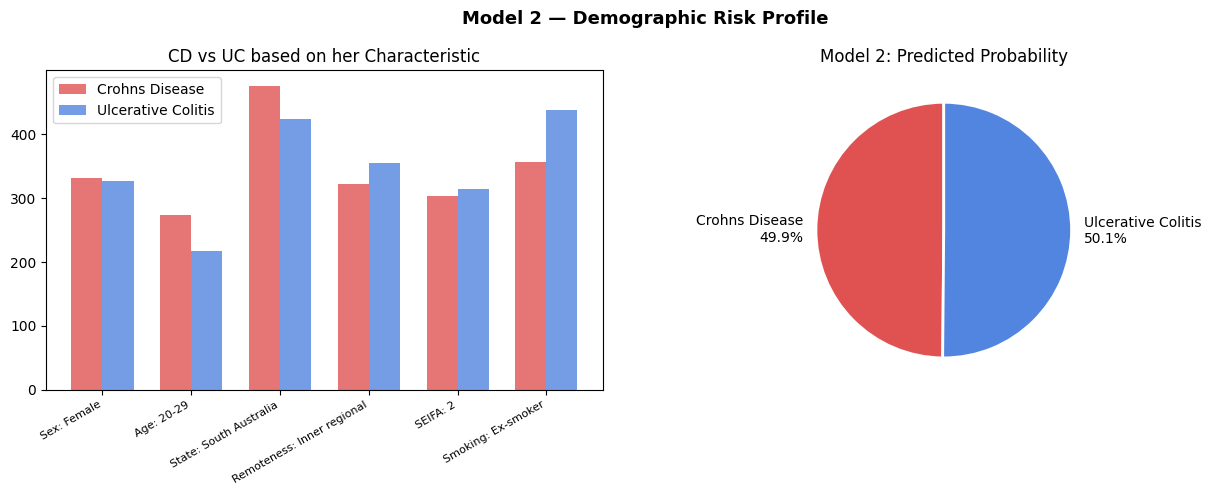

In [ ]:
friends_profile = {
    'Sex: Female':                (331, 326),
    'Age: 20-29':                 (274, 217),
    'State: South Australia':     (476, 424),
    'Remoteness: Inner regional': (322, 355),
    'SEIFA: 2':                   (304, 314),
    'Smoking: Ex-smoker':         (356, 438),
}

cd_scores = [v[0] for v in friends_profile.values()]
uc_scores = [v[1] for v in friends_profile.values()]

avg_cd = sum(cd_scores) / len(cd_scores)
avg_uc = sum(uc_scores) / len(uc_scores)
total = avg_cd + avg_uc
prob_cd = avg_cd / total * 100
prob_uc = avg_uc / total * 100

print(f"Crohn's Disease:    {prob_cd:.1f}%")
print(f"Ulcerative Colitis: {prob_uc:.1f}%")

# Plot
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: bar chart per characteristic
import numpy as np
labels = list(friends_profile.keys())
x = np.arange(len(labels))
w = 0.35
ax1.bar(x - w/2, cd_scores, w, label="Crohns Disease", color='#e05252', alpha=0.8)
ax1.bar(x + w/2, uc_scores, w, label='Ulcerative Colitis', color='#5285e0', alpha=0.8)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
ax1.set_title("CD vs UC based on her Characteristic")
ax1.legend()

# Right: pie
ax2.pie(
    [prob_cd, prob_uc],
    labels=[f"Crohns Disease\n{prob_cd:.1f}%", f"Ulcerative Colitis\n{prob_uc:.1f}%"],
    colors=['#e05252', '#5285e0'],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
ax2.set_title('Model 2: Predicted Probability')

plt.suptitle("Model 2 — Demographic Risk Profile", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Creating a model to detect if someone is healthy, or has Crohns or UC

She said she was not impressed with my findings. Anyways, enough about her, I want to go back to my original whole dataset and look at creating some models, which was actually my original focus before I got distracted. This is basically going to be me finding the best model that I could hypothetically compare her data to.

In [ ]:
# check data
print(df.shape)
print(df['diagnosis'].value_counts())

(3387, 571)
diagnosis
Crohns Disease        1608
Ulcerative Colitis     913
Healthy                866
Name: count, dtype: int64


In [ ]:
# this is following a similar format from one of my uni tasks
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings("ignore")

# Set X and y
X = df.select_dtypes('float64')
y = df['diagnosis']

# Impute missing values with median
imp = SimpleImputer(strategy='median')
X_imputed = imp.fit_transform(X)

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Classes:", le.classes_)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.20, random_state=100, stratify=y_encoded)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Classes: ['Crohns Disease' 'Healthy' 'Ulcerative Colitis']
Train size: (2709, 568)
Test size: (678, 568)


In [ ]:
# KNN ACCURACY
grid = {'n_neighbors':[3,5,10,15], 'weights':['uniform','distance']}
# Using smallest k-fold validation
cv = KFold(n_splits=2, shuffle=True, random_state=42)
grid_knn1 = GridSearchCV(KNeighborsClassifier(), grid, cv=cv, scoring='accuracy')
grid_knn1.fit(X_train, y_train)
print("2 k-fold CV score: ", grid_knn1.best_score_)
print("2 k-fold accuracy: ", grid_knn1.score(X_test, y_test))
print("Parameters: ", grid_knn1.best_params_)

# Using 5-fold validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid_knn2 = GridSearchCV(KNeighborsClassifier(), grid, cv=cv, scoring='accuracy')
grid_knn2.fit(X_train, y_train)
print("5 k-fold CV score: ", grid_knn2.best_score_)
print("5 k-fold accuracy: ", grid_knn2.score(X_test, y_test))
print("Parameters: ", grid_knn2.best_params_)

# Using 15-fold validation
cv = KFold(n_splits=15, shuffle=True, random_state=42)
grid_knn3 = GridSearchCV(KNeighborsClassifier(), grid, cv=cv, scoring='accuracy')
grid_knn3.fit(X_train, y_train)
print("15 k-fold CV score: ", grid_knn3.best_score_)
print("15 k-fold accuracy: ", grid_knn3.score(X_test, y_test))
print("Parameters: ", grid_knn3.best_params_)

2 k-fold CV score:  0.9258000076308002
2 k-fold accuracy:  0.9749262536873157
Parameters:  {'n_neighbors': 3, 'weights': 'distance'}
5 k-fold CV score:  0.9627190319962349
5 k-fold accuracy:  0.9749262536873157
Parameters:  {'n_neighbors': 3, 'weights': 'distance'}
15 k-fold CV score:  0.9678903212604869
15 k-fold accuracy:  0.9749262536873157
Parameters:  {'n_neighbors': 3, 'weights': 'distance'}


Really great results actually


In [ ]:
# DECISION TREE
print("F1")
grid = {'max_depth':[2, 5, 10, 20], 'criterion':['gini','entropy']}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), grid, cv=5, scoring='f1_macro')
grid_dt.fit(X_train, y_train)

print(grid_dt.best_params_)
print(grid_dt.best_score_)
print(grid_dt.score(X_test, y_test))

print("Accuracy")
grid = {'max_depth':[2, 5, 10, 20], 'criterion':['gini','entropy']}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), grid, cv=5, scoring='accuracy')
grid_dt.fit(X_train, y_train)

print(grid_dt.best_params_)
print(grid_dt.best_score_)
print(grid_dt.score(X_test, y_test))

F1
{'criterion': 'gini', 'max_depth': 20}
0.9287975383411746
0.96990598190997
Accuracy
{'criterion': 'gini', 'max_depth': 20}
0.9302228345758504
0.9734513274336283


In [ ]:
# RANDOM FOREST
grid = {'n_estimators':[50,100,150,200], 'min_samples_leaf':[2,10,20]}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, criterion='gini', max_features='sqrt'), grid, cv=5, scoring='f1_macro')
grid_rf.fit(X_train, y_train)

print("F1")
print(grid_rf.best_params_)
print(grid_rf.best_score_)
print(grid_rf.score(X_test, y_test))

print("Accuracy")
grid = {'n_estimators':[50,100,150,200], 'min_samples_leaf':[2,10,20]}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, criterion='gini', max_features='sqrt'), grid, cv=5, scoring='accuracy')
grid_rf.fit(X_train, y_train)
print(grid_rf.best_params_)
print(grid_rf.best_score_)
print(grid_rf.score(X_test, y_test))

F1
{'min_samples_leaf': 2, 'n_estimators': 200}
0.9770101212101064
0.9926849928579434
Accuracy
{'min_samples_leaf': 2, 'n_estimators': 200}
0.9771108579847352
0.9926253687315634


This is our best one so far! If only I could make my friend do metagenomic sequencing tests in order to see what it gives her.

In [ ]:
# ADABOOST
print("F1")
grid = {'n_estimators':[50,100,150,200]}

grid_ada = GridSearchCV(AdaBoostClassifier(random_state=42), grid, cv=5, scoring='f1_macro')
grid_ada.fit(X_train, y_train)

print(grid_ada.best_params_)
print(grid_ada.best_score_)
print(grid_ada.score(X_test, y_test))

print("Accuracy")
grid = {'n_estimators':[50,100,150,200]}

grid_ada = GridSearchCV(AdaBoostClassifier(random_state=42), grid, cv=5, scoring='accuracy')
grid_ada.fit(X_train, y_train)

print(grid_ada.best_params_)
print(grid_ada.best_score_)
print(grid_ada.score(X_test, y_test))

F1
{'n_estimators': 200}
0.786891454701863
0.8166194523135033
Accuracy
{'n_estimators': 200}
0.7965930250799735
0.8259587020648967


this isnt very good because AdaBoost performs worse with high-dimensional data.

In [ ]:
# STACKING ENSEMBLE
stack = StackingClassifier(
    estimators=[
        ('knn', grid_knn2.best_estimator_),
        ('rf', grid_rf.best_estimator_),
        ('dt', grid_dt.best_estimator_)
    ],
    final_estimator=LogisticRegression(max_iter=500)
)

stack.fit(X_train, y_train)
print("Stacking accuracy:", stack.score(X_test, y_test))

Stacking accuracy: 0.9882005899705014


Out of curiosity lets see which features are the strongest predictors, this can then be compared to our previous statement in a high rate of fecal calprotectin being a strong indicator.

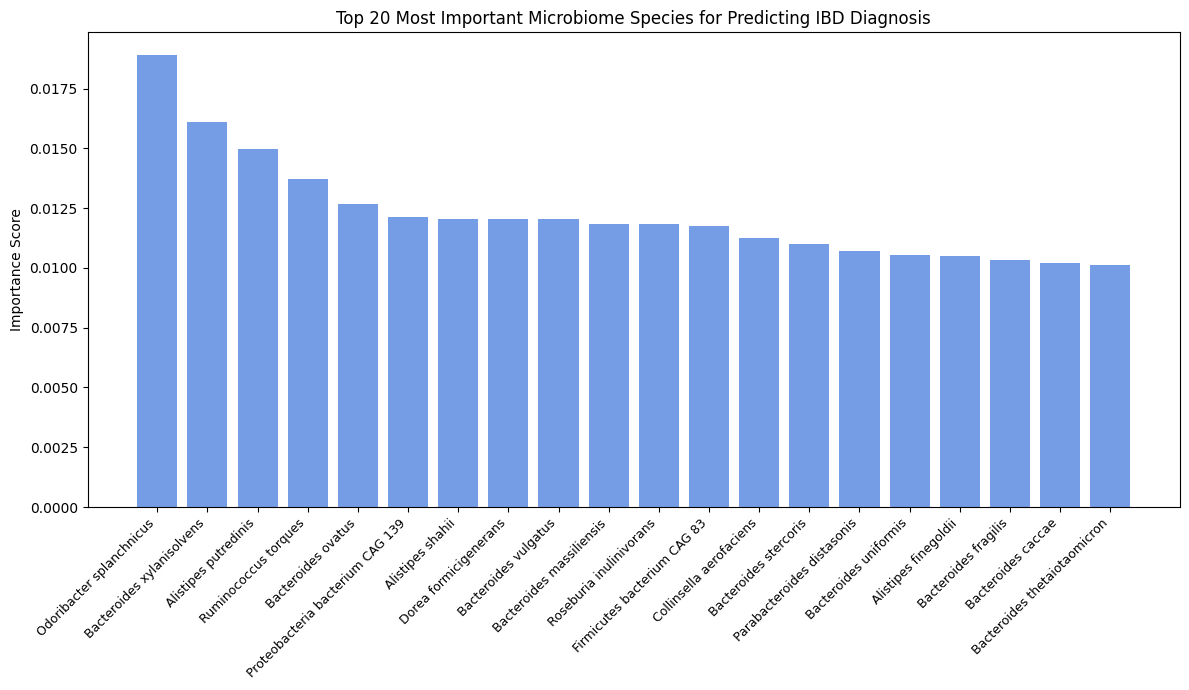


Top 10 species:
  Odoribacter splanchnicus: 0.0189
  Bacteroides xylanisolvens: 0.0161
  Alistipes putredinis: 0.0150
  Ruminococcus torques: 0.0137
  Bacteroides ovatus: 0.0127
  Proteobacteria bacterium CAG 139: 0.0121
  Alistipes shahii: 0.0121
  Dorea formicigenerans: 0.0120
  Bacteroides vulgatus: 0.0120
  Bacteroides massiliensis: 0.0118


In [ ]:
# FEATURE IMPORTANCE
import matplotlib.pyplot as plt
import numpy as np

# Get the best random forest model
best_rf = grid_rf.best_estimator_

# Get feature importances
feature_names = df.select_dtypes('float64').columns
importances = best_rf.feature_importances_

# Get top 20
indices = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(12, 7))
plt.bar(range(20), importances[indices], color='#5285e0', alpha=0.8)
plt.xticks(range(20), [feature_names[i] for i in indices], rotation=45, ha='right', fontsize=9)
plt.ylabel('Importance Score')
plt.title('Top 20 Most Important Microbiome Species for Predicting IBD Diagnosis')
plt.tight_layout()
plt.show()

print("\nTop 10 species:")
for i in indices[:10]:
    print(f"  {feature_names[i]}: {importances[i]:.4f}")

The scores are all quite low, obviously because there is so so many features.

In [ ]:
feature_names = df.select_dtypes('float64').columns
importances = best_rf.feature_importances_

fecalcal_idx = list(feature_names).index('fecalcal')
fecalcal_importance = importances[fecalcal_idx]

rank = sum(importances > fecalcal_importance) + 1

print(f"Fecalcal importance: {fecalcal_importance:.4f}")
print(f"Fecalcal rank: {rank} out of {len(feature_names)}")

Fecalcal importance: 0.0082
Fecalcal rank: 34 out of 568


OH wow!! Fecalcal is actually a lot higher than I expected, thats quite cool.